## **Cell 1: Imports and config**

In [1]:
%load_ext autoreload
%autoreload 2

import sys, time, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PROJECT_ROOT / "data").exists(), f"Wrong project root: {PROJECT_ROOT}"

CATEGORY = "metal_nut"
REPORT_DIR = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
MODEL_DIR = PROJECT_ROOT / "models"
for d in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Experiment settings
IMAGE_SIZE = 256
BATCH_SIZE = 8
EMBED_DIM = 1024          # baseline channel-pooled dim
EMBED_DIM_CONCAT = 1536   # new concatenated dim
POOL_KERNEL = 3
SEED = 42

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| data exists:", (PROJECT_ROOT / "data").exists())

Device: cuda | data exists: True


In [2]:
OVERWRITE = True   # <<< IMPORTANT: force rewrite so the new function is saved

FILES = {}

FILES["src/__init__.py"] = ""
FILES["src/data/__init__.py"] = ""
FILES["src/models/__init__.py"] = ""

# ---------------------------------------------------------------
# src/data/dataset.py   (unchanged)
# ---------------------------------------------------------------
FILES["src/data/dataset.py"] = r'''
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset
import torchvision.transforms as T

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


def load_splits(csv_path, project_root):
    """Read the saved split file and turn relative paths back into absolute ones."""
    df = pd.read_csv(csv_path)
    root = Path(project_root)
    df["path"] = df["path"].apply(lambda p: str(root / p))
    df["mask_path"] = df["mask_path"].apply(
        lambda p: str(root / p) if isinstance(p, str) and p else None
    )
    return df


class MVTecDataset(Dataset):
    """Returns image, mask, label, defect_type, path for one MVTec AD category."""

    def __init__(self, records, image_size=256):
        self.records = records.reset_index(drop=True)
        self.image_size = image_size
        self.img_tf = T.Compose([
            T.Resize((image_size, image_size),
                     interpolation=T.InterpolationMode.BILINEAR),
            T.ToTensor(),
            T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records.iloc[idx]
        image = self.img_tf(Image.open(r["path"]).convert("RGB"))

        mp = r["mask_path"]
        if isinstance(mp, str) and mp != "":
            m = Image.open(mp).convert("L")
            m = m.resize((self.image_size, self.image_size),
                         Image.Resampling.NEAREST)
            mask = torch.from_numpy(
                (np.array(m) > 0).astype(np.float32)
            ).unsqueeze(0)
        else:
            mask = torch.zeros(1, self.image_size, self.image_size)

        return {
            "image": image,
            "mask": mask,
            "label": int(r["label"]),
            "defect_type": r["defect_type"],
            "path": r["path"],
        }
'''

# ---------------------------------------------------------------
# src/models/feature_extractor.py  (WITH patch_embeddings_concat)
# ---------------------------------------------------------------
FILES["src/models/feature_extractor.py"] = r'''
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights


class FeatureExtractor(nn.Module):
    """Frozen WideResNet50-2 that returns layer2 and layer3 feature maps."""

    def __init__(self):
        super().__init__()
        weights = Wide_ResNet50_2_Weights.IMAGENET1K_V1
        backbone = wide_resnet50_2(weights=weights)

        self.stem = nn.Sequential(
            backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
            backbone.layer1,
        )
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3

        for p in self.parameters():
            p.requires_grad = False
        self.eval()

    def forward(self, x):
        x = self.stem(x)
        f2 = self.layer2(x)
        f3 = self.layer3(f2)
        return f2, f3


def patch_embeddings(features, out_dim=1024, pool_kernel=3):
    """
    Baseline: local pooling -> upsample layer3 -> concat (1536) ->
    adaptive_avg_pool1d to out_dim (1024).
    """
    f2, f3 = features
    pad = pool_kernel // 2
    f2 = F.avg_pool2d(f2, pool_kernel, stride=1, padding=pad)
    f3 = F.avg_pool2d(f3, pool_kernel, stride=1, padding=pad)
    f3 = F.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
    x = torch.cat([f2, f3], dim=1)            # (B, 1536, H, W)
    B, C, H, W = x.shape
    x = x.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
    x = F.adaptive_avg_pool1d(x, out_dim).squeeze(1)
    return x.reshape(B, H * W, out_dim), (H, W)


def patch_embeddings_concat(features, pool_kernel=3):
    """
    NEW: same local pooling + upsample, but KEEP all 1536 channels.
    Returns (B, H*W, 1536), (H, W).
    """
    f2, f3 = features
    pad = pool_kernel // 2
    f2 = F.avg_pool2d(f2, pool_kernel, stride=1, padding=pad)
    f3 = F.avg_pool2d(f3, pool_kernel, stride=1, padding=pad)
    f3 = F.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
    x = torch.cat([f2, f3], dim=1)            # (B, 1536, H, W)
    B, C, H, W = x.shape
    assert C == 1536, f"Expected 1536 channels, got {C}"
    x = x.permute(0, 2, 3, 1).reshape(B, H * W, C)
    return x, (H, W)


@torch.inference_mode()
def extract_dataset(model, loader, device, out_dim=1024, pool_kernel=3):
    """Run a whole DataLoader through the baseline extractor."""
    chunks = []
    hw = None
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        emb, hw = patch_embeddings(model(x), out_dim, pool_kernel)
        chunks.append(emb.cpu())
    return torch.cat(chunks), hw


@torch.inference_mode()
def extract_dataset_concat(model, loader, device, pool_kernel=3):
    """Run a whole DataLoader through the concatenated extractor."""
    chunks = []
    hw = None
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        emb, hw = patch_embeddings_concat(model(x), pool_kernel)
        chunks.append(emb.cpu())
    return torch.cat(chunks), hw
'''

for rel, content in FILES.items():
    path = PROJECT_ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and not OVERWRITE:
        print("kept   :", rel)
    else:
        path.write_text(content, encoding="utf-8")
        print("written:", rel)

written: src/__init__.py
written: src/data/__init__.py
written: src/models/__init__.py
written: src/data/dataset.py
written: src/models/feature_extractor.py


## **Cell 2: Create the src files**

In [ ]:
import sys, importlib

sys.path.insert(0, str(PROJECT_ROOT))

# Remove any cached modules so the new file is picked up
for mod_name in ["src", "src.data", "src.data.dataset",
                 "src.models", "src.models.feature_extractor"]:
    if mod_name in sys.modules:
        del sys.modules[mod_name]

import src
assert Path(src.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()), \
    f"Wrong src: {src.__file__}"

from src.data.dataset import MVTecDataset, load_splits, IMAGENET_MEAN, IMAGENET_STD
from src.models.feature_extractor import (
    FeatureExtractor,
    patch_embeddings,
    patch_embeddings_concat,
    extract_dataset,
    extract_dataset_concat,
)

# Confirm the new function exists
import inspect
print("patch_embeddings_concat source file:",
      inspect.getsourcefile(patch_embeddings_concat))

splits = load_splits(REPORT_DIR / f"{CATEGORY}_splits.csv", PROJECT_ROOT)
train_fit  = splits[splits.role == "fit"]
val_normal = splits[splits.role == "val_normal"]
test_df    = splits[splits.role == "test"]

assert (len(train_fit), len(val_normal), len(test_df)) == (198, 22, 115), \
    "Unexpected split sizes"
print("fit / val_normal / test:", len(train_fit), "/", len(val_normal), "/", len(test_df))

train_ds = MVTecDataset(train_fit, IMAGE_SIZE)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=True)

kept    : src/__init__.py
kept    : src/data/__init__.py
kept    : src/models/__init__.py
kept    : src/data/dataset.py
kept    : src/models/feature_extractor.py


## **Cell 3: Import from src, load the splits, build the DataLoader**

In [9]:
sys.path.insert(0, str(PROJECT_ROOT))      # insert at the front so OUR src wins

import src
assert Path(src.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()), f"Wrong src: {src.__file__}"

from src.data.dataset import MVTecDataset, load_splits, IMAGENET_MEAN, IMAGENET_STD
from src.models.feature_extractor import FeatureExtractor, patch_embeddings, extract_dataset,patch_embeddings_concat, extract_dataset_concat

splits     = load_splits(REPORT_DIR / f"{CATEGORY}_splits.csv", PROJECT_ROOT)
train_fit  = splits[splits.role == "fit"]
val_normal = splits[splits.role == "val_normal"]
test_df    = splits[splits.role == "test"]

assert (len(train_fit), len(val_normal), len(test_df)) == (198, 22, 115), "Unexpected split sizes"
print("fit / val_normal / test:", len(train_fit), "/", len(val_normal), "/", len(test_df))

train_ds     = MVTecDataset(train_fit, IMAGE_SIZE)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

fit / val_normal / test: 198 / 22 / 115


## **Cell 4: Build the frozen extractor**

In [4]:
extractor = FeatureExtractor().to(device)

n_params    = sum(p.numel() for p in extractor.parameters())
n_trainable = sum(p.numel() for p in extractor.parameters() if p.requires_grad)
print(f"Parameters: {n_params/1e6:.1f} M | trainable: {n_trainable}")
print("Training mode:", extractor.training)

Parameters: 24.9 M | trainable: 0
Training mode: False


## **Cell 5: One batch through the extractor**

In [5]:
batch = next(iter(train_loader))
x = batch["image"].to(device)
torch.cuda.reset_peak_memory_stats()

with torch.inference_mode():
    f2, f3 = extractor(x)

    # Baseline (1024-dim) — pass tuple (f2, f3) as ONE argument
    emb_baseline, grid_baseline = patch_embeddings((f2, f3), EMBED_DIM, POOL_KERNEL)

    # NEW concatenated (1536-dim)
    emb_concat, grid_concat = patch_embeddings_concat((f2, f3), POOL_KERNEL)

print("input            :", tuple(x.shape))
print("layer2 map       :", tuple(f2.shape))
print("layer3 map       :", tuple(f3.shape))
print("baseline embed   :", tuple(emb_baseline.shape),
      f"-> {grid_baseline[0]}x{grid_baseline[1]} grid, 1024-dim")
print("concat embed     :", tuple(emb_concat.shape),
      f"-> {grid_concat[0]}x{grid_concat[1]} grid, 1536-dim")
print("peak GPU memory (MB):", round(torch.cuda.max_memory_allocated() / 1e6, 1))

# Shape and consistency checks
assert emb_concat.shape == (x.shape[0], grid_concat[0] * grid_concat[1], 1536), \
    f"Wrong concat shape: {emb_concat.shape}"
assert grid_concat == grid_baseline, "Grids must match"
assert torch.isfinite(emb_concat).all(), "Non-finite values in concat embeddings"
print("\n\u2713 Both embedding methods produced correct shapes")

input            : (8, 3, 256, 256)
layer2 map       : (8, 512, 32, 32)
layer3 map       : (8, 1024, 16, 16)
baseline embed   : (8, 1024, 1024) -> 32x32 grid, 1024-dim
concat embed     : (8, 1024, 1536) -> 32x32 grid, 1536-dim
peak GPU memory (MB): 284.2

✓ Both embedding methods produced correct shapes


## **Cell 6: Sanity checks (frozen, deterministic, no NaN)**

In [6]:
with torch.inference_mode():
    f2, f3 = extractor(x)
    emb_base2, _   = patch_embeddings((f2, f3), EMBED_DIM, POOL_KERNEL)
    emb_concat2, _ = patch_embeddings_concat((f2, f3), POOL_KERNEL)

print("Baseline identical on repeat run :", torch.allclose(emb_baseline, emb_base2))
print("Concat identical on repeat run   :", torch.allclose(emb_concat, emb_concat2))

print("Baseline contains NaN            :", torch.isnan(emb_baseline).any().item())
print("Concat contains NaN              :", torch.isnan(emb_concat).any().item())

print("Trainable parameters             :",
      sum(p.numel() for p in extractor.parameters() if p.requires_grad))

print(f"Baseline mean/std : {emb_baseline.mean().item():.5f} / {emb_baseline.std().item():.5f}")
print(f"Concat   mean/std : {emb_concat.mean().item():.5f} / {emb_concat.std().item():.5f}")

assert emb_concat.shape[1] == emb_baseline.shape[1], "Patch counts must match"
print("\n\u2713 Sanity checks passed for both embeddings")

Baseline identical on repeat run : True
Concat identical on repeat run   : True
Baseline contains NaN            : False
Concat contains NaN              : False
Trainable parameters             : 0
Baseline mean/std : 0.06503 / 0.06631
Concat   mean/std : 0.06402 / 0.09020

✓ Sanity checks passed for both embeddings


## **Cell 7: What do patch features look like? (PCA to color)**

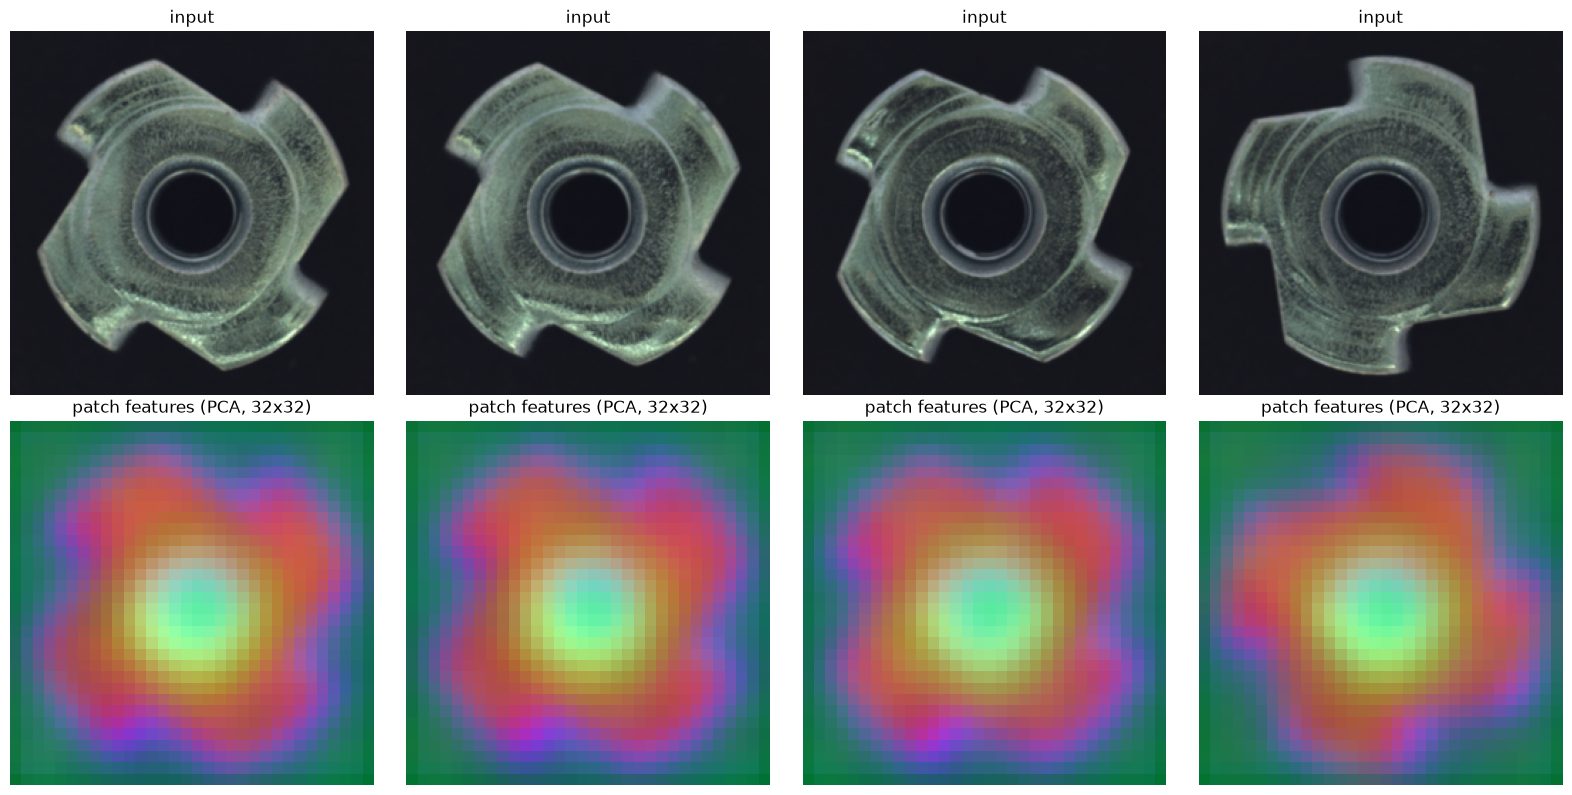

In [7]:
from sklearn.decomposition import PCA

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

n = 4
patches = emb_baseline[:n].reshape(-1, EMBED_DIM).cpu().numpy()
proj = PCA(n_components=3, random_state=SEED).fit_transform(patches).reshape(n, 32, 32, 3)
proj = (proj - proj.min()) / (proj.max() - proj.min() + 1e-8)

fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
for i in range(n):
    axes[0, i].imshow(denorm(x[i]))
    axes[0, i].set_title("input")
    axes[0, i].axis("off")
    axes[1, i].imshow(proj[i])
    axes[1, i].set_title(f"patch features (PCA, 32x32)")
    axes[1, i].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_feature_pca.png", dpi=150)
plt.show()

## **Cell 8: Extract features for all 198 normal training images**

In [10]:
# --- Baseline (1024-dim) ---
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
t0 = time.time()
train_emb_base, (H, W) = extract_dataset(
    extractor, train_loader, device, EMBED_DIM, POOL_KERNEL
)
torch.cuda.synchronize()
dt_base = time.time() - t0

n_images, patches_per_img, dim = train_emb_base.shape
print("=== Baseline (1024-dim, channel-pooled) ===")
print("embeddings tensor   :", tuple(train_emb_base.shape))
print("total patches       :", n_images * patches_per_img)
print("size in memory (GB) :", round(train_emb_base.numel() * 4 / 1e9, 3))
print("extraction time (s) :", round(dt_base, 1),
      f"({1000*dt_base/n_images:.1f} ms/image)")
print("peak GPU memory (MB):", round(torch.cuda.max_memory_allocated() / 1e6, 1))

# --- Concatenated (1536-dim) ---
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
t0 = time.time()
train_emb_concat, (H_c, W_c) = extract_dataset_concat(
    extractor, train_loader, device, POOL_KERNEL
)
torch.cuda.synchronize()
dt_concat = time.time() - t0

n_images_c, patches_per_img_c, dim_c = train_emb_concat.shape
print("\n=== Concatenated (1536-dim, no channel pooling) ===")
print("embeddings tensor   :", tuple(train_emb_concat.shape))
print("total patches       :", n_images_c * patches_per_img_c)
print("size in memory (GB) :", round(train_emb_concat.numel() * 4 / 1e9, 3))
print("extraction time (s) :", round(dt_concat, 1),
      f"({1000*dt_concat/n_images_c:.1f} ms/image)")
print("peak GPU memory (MB):", round(torch.cuda.max_memory_allocated() / 1e6, 1))

assert patches_per_img == patches_per_img_c, \
    "Patch counts must match between methods"
assert dim_c == EMBED_DIM_CONCAT, f"Concat dim mismatch: {dim_c}"
print("\n\u2713 Both embeddings extracted successfully")

=== Baseline (1024-dim, channel-pooled) ===
embeddings tensor   : (198, 1024, 1024)
total patches       : 202752
size in memory (GB) : 0.83
extraction time (s) : 6.0 (30.5 ms/image)
peak GPU memory (MB): 517.0

=== Concatenated (1536-dim, no channel pooling) ===
embeddings tensor   : (198, 1024, 1536)
total patches       : 202752
size in memory (GB) : 1.246
extraction time (s) : 6.5 (33.0 ms/image)
peak GPU memory (MB): 483.4

✓ Both embeddings extracted successfully


## **Cell 9: Save the extraction settings**

In [11]:
meta = {
    "category": CATEGORY,
    "backbone": "wide_resnet50_2 (ImageNet1K_V1, frozen)",
    "layers": ["layer2", "layer3"],
    "image_size": IMAGE_SIZE,
    "pool_kernel": POOL_KERNEL,
    "feature_grid": [int(H), int(W)],
    "n_train_images": int(n_images),
    "patches_per_image": int(patches_per_img),
    "total_patches": int(n_images * patches_per_img),
    "torch": torch.__version__,
    "seed": SEED,
    "baseline": {
        "method": "concat_then_channel_adaptive_avg_pool",
        "embed_dim": 1024,
        "extraction_seconds": round(dt_base, 2),
        "peak_gpu_mb": round(torch.cuda.max_memory_allocated() / 1e6, 1),
    },
    "alternative": {
        "method": "aligned_concat_preserve_all_channels",
        "embed_dim": 1536,
        "extraction_seconds": round(dt_concat, 2),
        "peak_gpu_mb": round(torch.cuda.max_memory_allocated() / 1e6, 1),
    },
}

with open(REPORT_DIR / f"{CATEGORY}_feature_extraction_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

torch.save(train_emb_base,   MODEL_DIR / f"{CATEGORY}_train_emb_baseline_1024.pt")
torch.save(train_emb_concat, MODEL_DIR / f"{CATEGORY}_train_emb_concat_1536.pt")

print("Saved both embedding tensors.")
print(json.dumps(meta, indent=2))

Saved both embedding tensors.
{
  "category": "metal_nut",
  "backbone": "wide_resnet50_2 (ImageNet1K_V1, frozen)",
  "layers": [
    "layer2",
    "layer3"
  ],
  "image_size": 256,
  "pool_kernel": 3,
  "feature_grid": [
    32,
    32
  ],
  "n_train_images": 198,
  "patches_per_image": 1024,
  "total_patches": 202752,
  "torch": "2.7.1+cu118",
  "seed": 42,
  "baseline": {
    "method": "concat_then_channel_adaptive_avg_pool",
    "embed_dim": 1024,
    "extraction_seconds": 6.05,
    "peak_gpu_mb": 483.4
  },
  "alternative": {
    "method": "aligned_concat_preserve_all_channels",
    "embed_dim": 1536,
    "extraction_seconds": 6.54,
    "peak_gpu_mb": 483.4
  }
}
